In [1]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

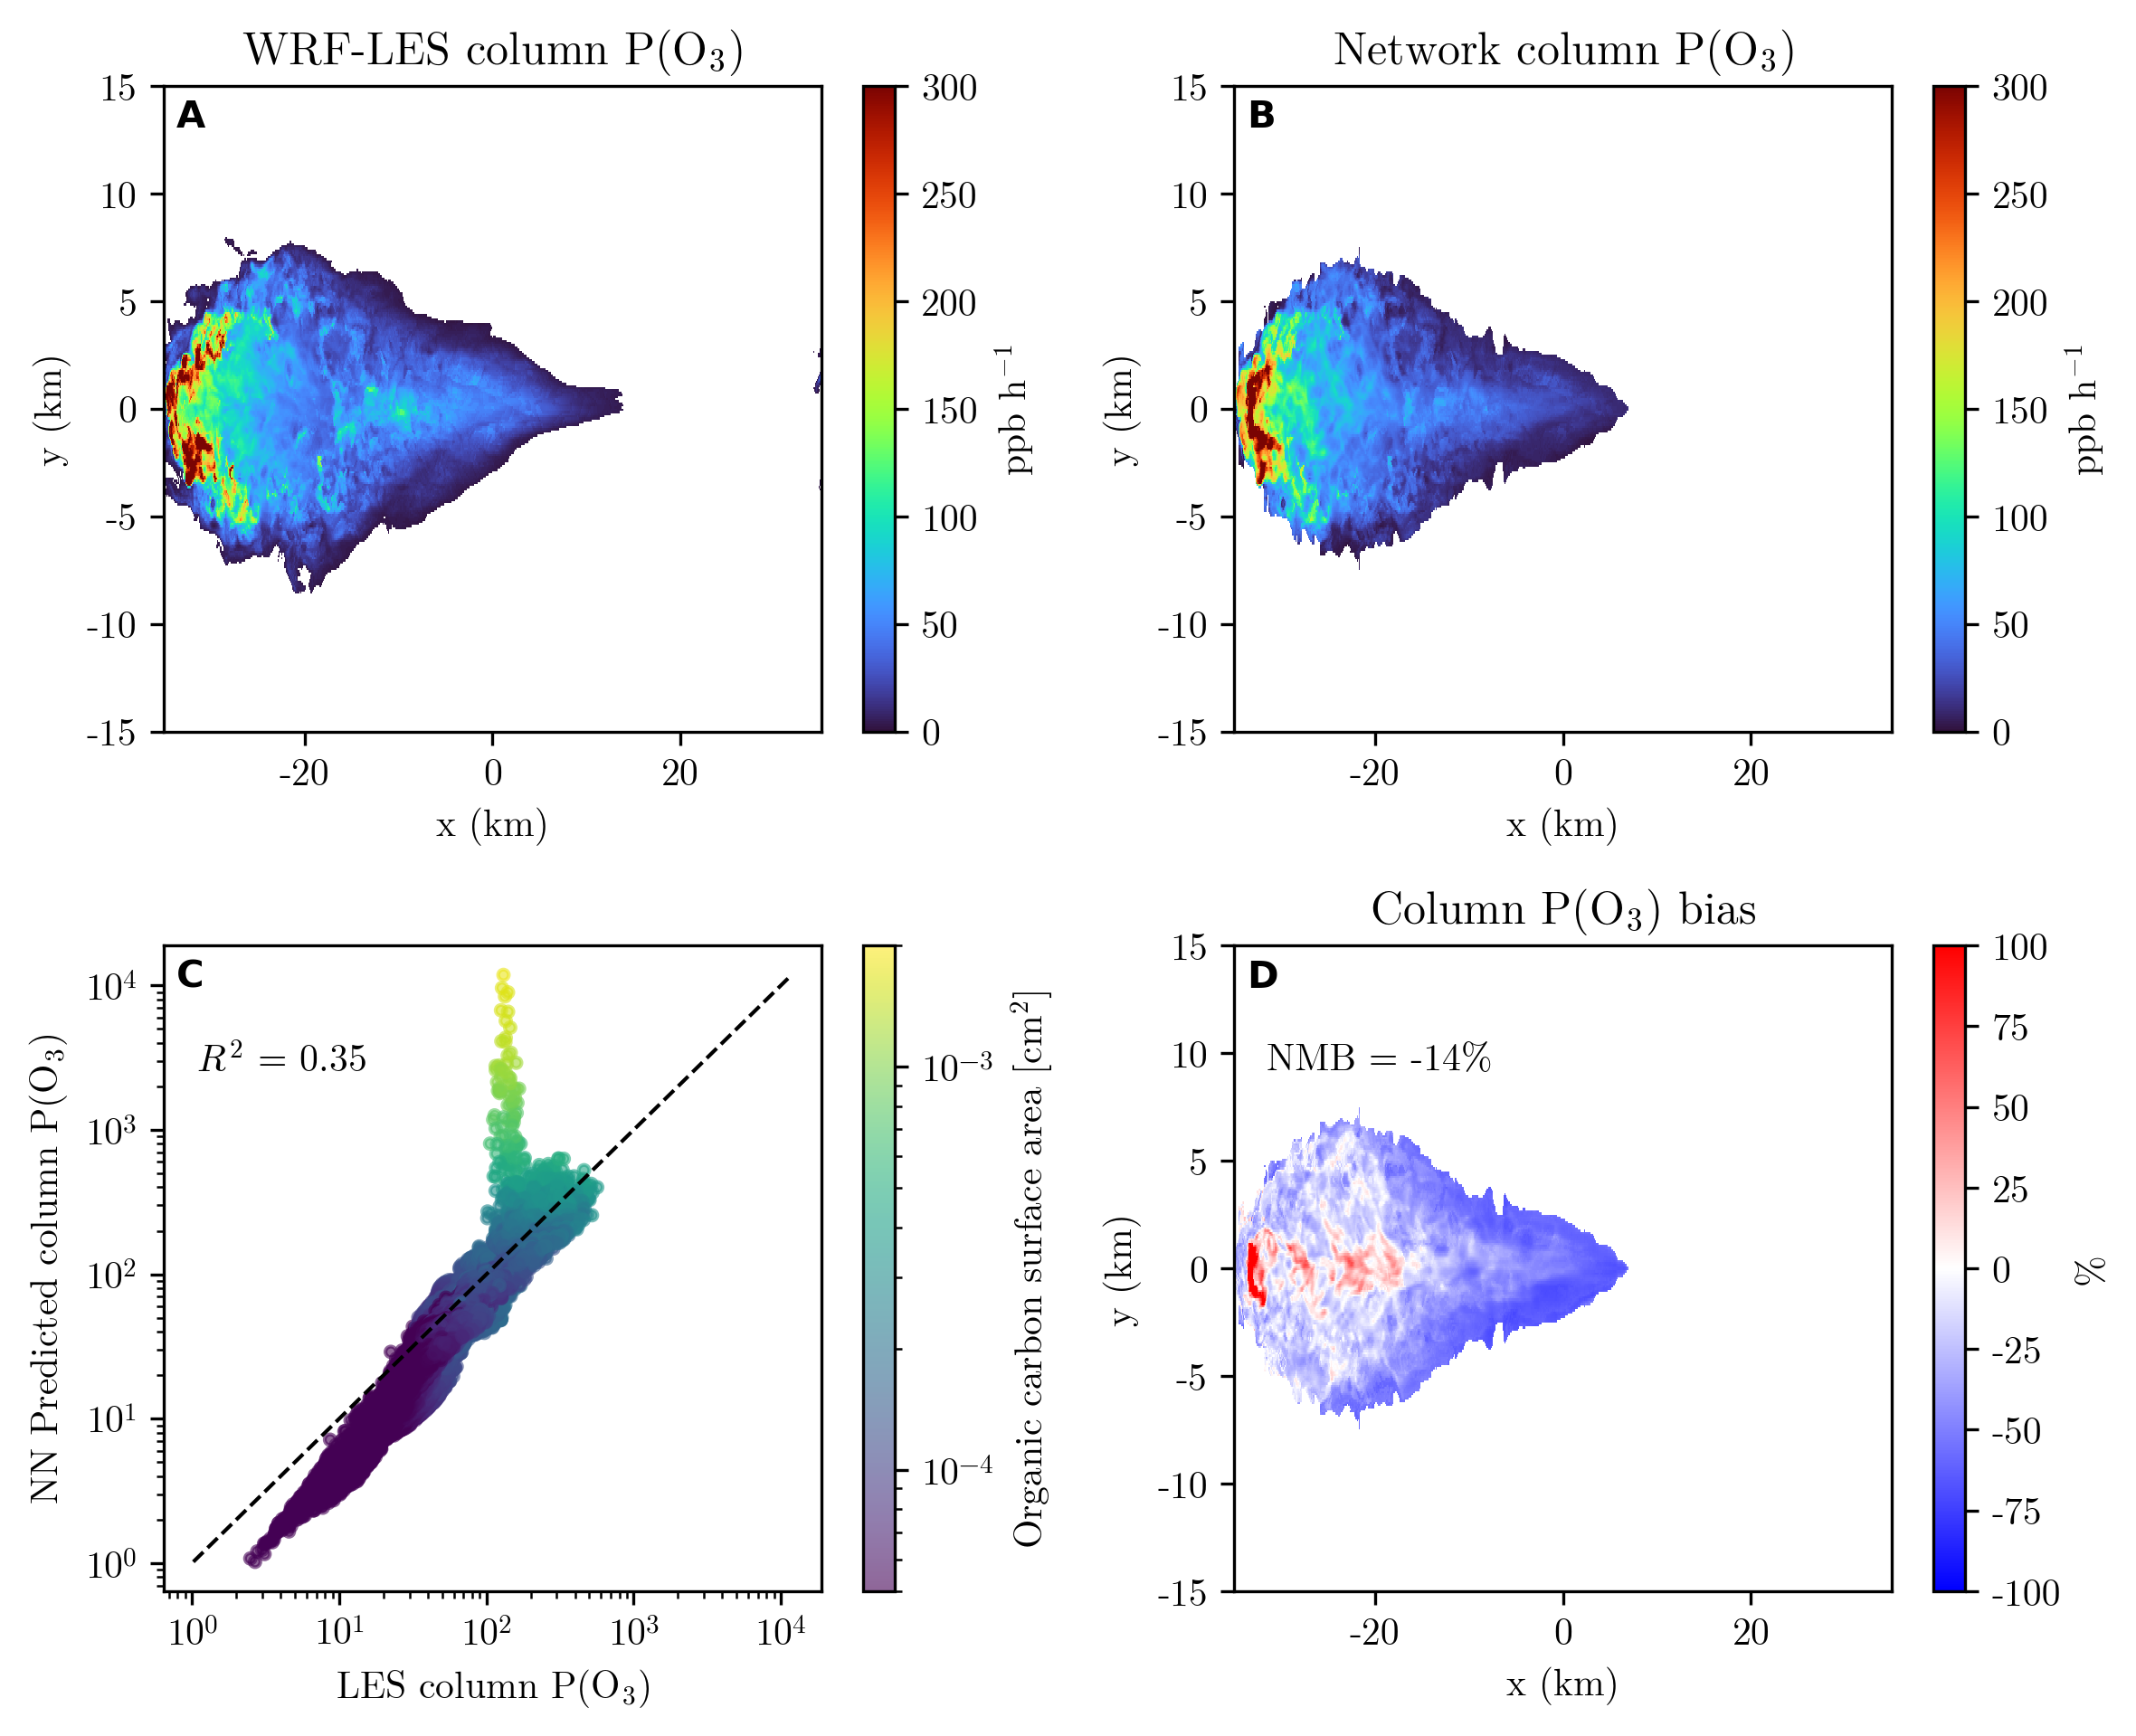

In [2]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.colors import LogNorm
from sklearn.metrics import r2_score

LES_DATASET = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data/les_williams.nc")
NEEDED = ["column_pO3", "column_pO3_pred", "column_pO3_pct_bias", "oc_srf_area"]

ds = xr.open_dataset(LES_DATASET)
missing = [name for name in NEEDED if name not in ds]
if missing:
    raise FileNotFoundError(", ".join(missing) + " missing from " + LES_DATASET.name)

def to_km(values):
    values = np.asarray(values)
    return values / 1000.0 if np.nanmax(values) > 100 else values

x_km = to_km(ds["x"].values if "x" in ds.coords else np.arange(ds.sizes["x"]))
y_km = to_km(ds["y"].values if "y" in ds.coords else np.arange(ds.sizes["y"]))
valid = np.isfinite(ds["column_pO3"]) & np.isfinite(ds["column_pO3_pred"]) & (ds["column_pO3"] > 0) & (ds["column_pO3_pred"] > 0)
y_true = ds["column_pO3"].where(valid).values.ravel()
y_pred = ds["column_pO3_pred"].where(valid).values.ravel()
y_true = y_true[np.isfinite(y_true)]
y_pred = y_pred[np.isfinite(y_pred)]
color = ds["oc_srf_area"].where(valid).values.ravel()
color = color[np.isfinite(color)]

fig, axes = plt.subplots(2, 2, figsize=(8, 6.5), dpi=300)
axes = axes.ravel()
for ax, field, title, vmin, vmax, cmap, label in (
    (axes[0], ds["column_pO3"], r"WRF-LES column P(O$_3$)", 0, 300, "turbo", "ppb h$^{-1}$"),
    (axes[1], ds["column_pO3_pred"], r"Network column P(O$_3$)", 0, 300, "turbo", "ppb h$^{-1}$"),
    (axes[3], ds["column_pO3_pct_bias"], r"Column P(O$_3$) bias", -100, 100, "bwr", "%"),
):
    mesh = ax.pcolormesh(x_km, y_km, field, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
    fig.colorbar(mesh, ax=ax, label=label)
    ax.set_title(title)
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")

norm = LogNorm(vmin=5e-5, vmax=2e-3)
artist = axes[2].scatter(y_true, y_pred, s=8, c=color[: len(y_true)], cmap="viridis", norm=norm, alpha=0.6)
fig.colorbar(artist, ax=axes[2], label=r"Organic carbon surface area [cm$^2$]")
low = min(y_true.min(), y_pred.min())
high = max(y_true.max(), y_pred.max())
axes[2].plot([low, high], [low, high], "k--", lw=1)
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlabel(r"LES column P(O$_3$)")
axes[2].set_ylabel(r"NN Predicted column P(O$_3$)")
axes[2].text(0.05, 0.85, f"$R^2$ = {r2_score(np.log10(y_true), np.log10(y_pred)):.2f}", transform=axes[2].transAxes, va="top")
nmb = 100.0 * np.sum(y_pred - y_true) / np.sum(y_true)
axes[3].text(0.05, 0.85, f"NMB = {nmb:.0f}%", transform=axes[3].transAxes, va="top")
for letter, ax in zip("ABCD", axes):
    ax.text(0.02, 0.98, letter, transform=ax.transAxes, va="top", fontweight="bold", fontfamily="Arial")
fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/fig05.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/fig05.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
